In [3]:

from pathlib import Path
import os
import json

# Project directories
ROOT = Path("/home/cse-sdpl/Downloads")

E0_DIR = ROOT / "CMX_Original"
E1_DIR = ROOT / "CMX_E1"
E2_DIR = ROOT / "CMX_E2"

# Dataset and prediction directories
DATASET_DIR = E0_DIR / "datasets" / "TDD"
RGB_DIR = DATASET_DIR / "RGB"
THERMAL_DIR = DATASET_DIR / "Thermal"
LABEL_DIR = DATASET_DIR / "Label"
VAL_FILE = DATASET_DIR / "val.txt"

E0_PRED_DIR = E0_DIR / "predictions_TDD_epoch100"
E1_PRED_DIR = E1_DIR / "e1_predictions"
E2_PRED_DIR = E2_DIR / "predictions_TDD_E2_epoch100"

RESULTS_DIR = E2_DIR / "comparison_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Check important paths
paths = {
    "E0 project": E0_DIR,
    "E1 project": E1_DIR,
    "E2 project": E2_DIR,
    "RGB images": RGB_DIR,
    "Thermal images": THERMAL_DIR,
    "Ground truth": LABEL_DIR,
    "Validation split": VAL_FILE,
    "E0 predictions": E0_PRED_DIR,
    "E1 predictions": E1_PRED_DIR,
    "E2 predictions": E2_PRED_DIR,
}

print("=" * 65)
print("CMX E0 vs E1 vs E2 — COMPARISON SETUP")
print("=" * 65)

for name, path in paths.items():
    exists = path.exists()
    print(f"{name:20} | Exists: {exists}")
    print(f"  {path}")

# Count PNG masks in each prediction folder
print("\n" + "=" * 65)
print("PREDICTION FILE COUNTS")
print("=" * 65)

for name, folder in [
    ("E0", E0_PRED_DIR),
    ("E1", E1_PRED_DIR),
    ("E2", E2_PRED_DIR),
]:
    count = len(list(folder.rglob("*.png"))) if folder.exists() else 0
    print(f"{name}: {count} PNG masks")

# Read validation IDs
if VAL_FILE.exists():
    val_ids = [
        line.strip().split()[0]
        for line in VAL_FILE.read_text().splitlines()
        if line.strip()
    ]
    print("\nValidation IDs:", len(val_ids))
    print("First five IDs:", val_ids[:5])

print("\nResults will be saved to:", RESULTS_DIR)


CMX E0 vs E1 vs E2 — COMPARISON SETUP
E0 project           | Exists: True
  /home/cse-sdpl/Downloads/CMX_Original
E1 project           | Exists: True
  /home/cse-sdpl/Downloads/CMX_E1
E2 project           | Exists: True
  /home/cse-sdpl/Downloads/CMX_E2
RGB images           | Exists: True
  /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB
Thermal images       | Exists: True
  /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Thermal
Ground truth         | Exists: True
  /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label
Validation split     | Exists: True
  /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/val.txt
E0 predictions       | Exists: True
  /home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100
E1 predictions       | Exists: True
  /home/cse-sdpl/Downloads/CMX_E1/e1_predictions
E2 predictions       | Exists: True
  /home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100

PREDICTION FILE COUNTS
E0: 392 PNG masks
E1: 392 PNG masks
E2: 392 PNG masks

V

In [4]:
 # matching image IDs

In [5]:

from pathlib import Path

def get_png_ids(folder):
    return {
        p.stem for p in Path(folder).rglob("*.png")
    }

e0_ids = get_png_ids(E0_PRED_DIR)
e1_ids = get_png_ids(E1_PRED_DIR)
e2_ids = get_png_ids(E2_PRED_DIR)

val_set = set(val_ids)

print("E0 prediction IDs:", len(e0_ids))
print("E1 prediction IDs:", len(e1_ids))
print("E2 prediction IDs:", len(e2_ids))
print("Validation IDs:", len(val_set))

print("\nE0 missing validation IDs:", len(val_set - e0_ids))
print("E1 missing validation IDs:", len(val_set - e1_ids))
print("E2 missing validation IDs:", len(val_set - e2_ids))

print("\nIDs common to E0, E1, E2 and validation:",
      len(e0_ids & e1_ids & e2_ids & val_set))

print("\nExample IDs common to all experiments:")
print(sorted(e0_ids & e1_ids & e2_ids & val_set)[:10])

assert e0_ids == val_set, "E0 prediction IDs do not exactly match validation IDs."
assert e1_ids == val_set, "E1 prediction IDs do not exactly match validation IDs."
assert e2_ids == val_set, "E2 prediction IDs do not exactly match validation IDs."

print("\nSUCCESS: All three experiments match the same validation IDs.")


E0 prediction IDs: 392
E1 prediction IDs: 392
E2 prediction IDs: 392
Validation IDs: 392

E0 missing validation IDs: 0
E1 missing validation IDs: 0
E2 missing validation IDs: 0

IDs common to E0, E1, E2 and validation: 392

Example IDs common to all experiments:
['00498D', '00499D', '00500D', '00501D', '00502D', '00503D', '00504D', '00505D', '00506D', '00507D']

SUCCESS: All three experiments match the same validation IDs.


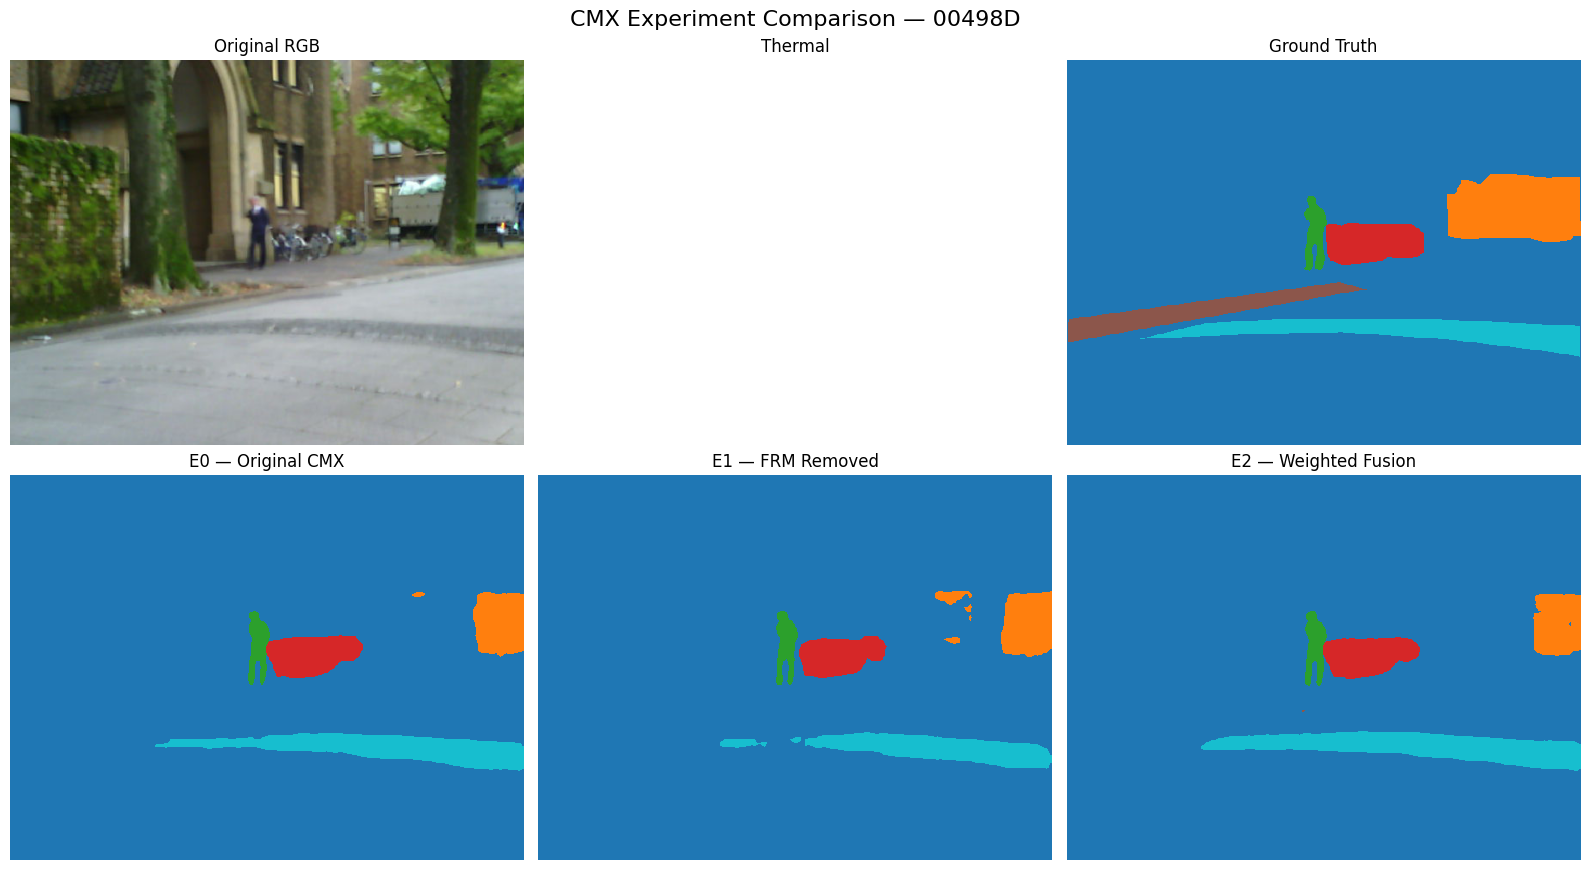

Saved figure: /home/cse-sdpl/Downloads/CMX_E2/comparison_results/visual_comparison_00498D.png


In [7]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Choose a validation image
IMAGE_ID = "00498D"

def find_png(folder, image_id):
    matches = list(Path(folder).rglob(f"{image_id}.png"))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one {image_id}.png in {folder}, found {len(matches)}"
        )
    return matches[0]

rgb = np.array(Image.open(find_png(RGB_DIR, IMAGE_ID)).convert("RGB"))
thermal = np.array(Image.open(find_png(THERMAL_DIR, IMAGE_ID)).convert("L"))
gt = np.array(Image.open(find_png(LABEL_DIR, IMAGE_ID)))
e0 = np.array(Image.open(find_png(E0_PRED_DIR, IMAGE_ID)))
e1 = np.array(Image.open(find_png(E1_PRED_DIR, IMAGE_ID)))
e2 = np.array(Image.open(find_png(E2_PRED_DIR, IMAGE_ID)))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

panels = [
    ("Original RGB", rgb, None),
    ("Thermal", thermal, "gray"),
    ("Ground Truth", gt, "tab10"),
    ("E0 — Original CMX", e0, "tab10"),
    ("E1 — FRM Removed", e1, "tab10"),
    ("E2 — Weighted Fusion", e2, "tab10"),
]

for ax, (title, image, cmap) in zip(axes.flat, panels):
    if cmap:
        ax.imshow(image, cmap=cmap, vmin=0, vmax=8,
                  interpolation="nearest")
    else:
        ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(f"CMX Experiment Comparison — {IMAGE_ID}", fontsize=16)
plt.tight_layout()

save_path = RESULTS_DIR / f"visual_comparison_{IMAGE_ID}.png"
plt.savefig(save_path, dpi=250, bbox_inches="tight")
plt.show()

print("Saved figure:", save_path)


New image ID: 00510D


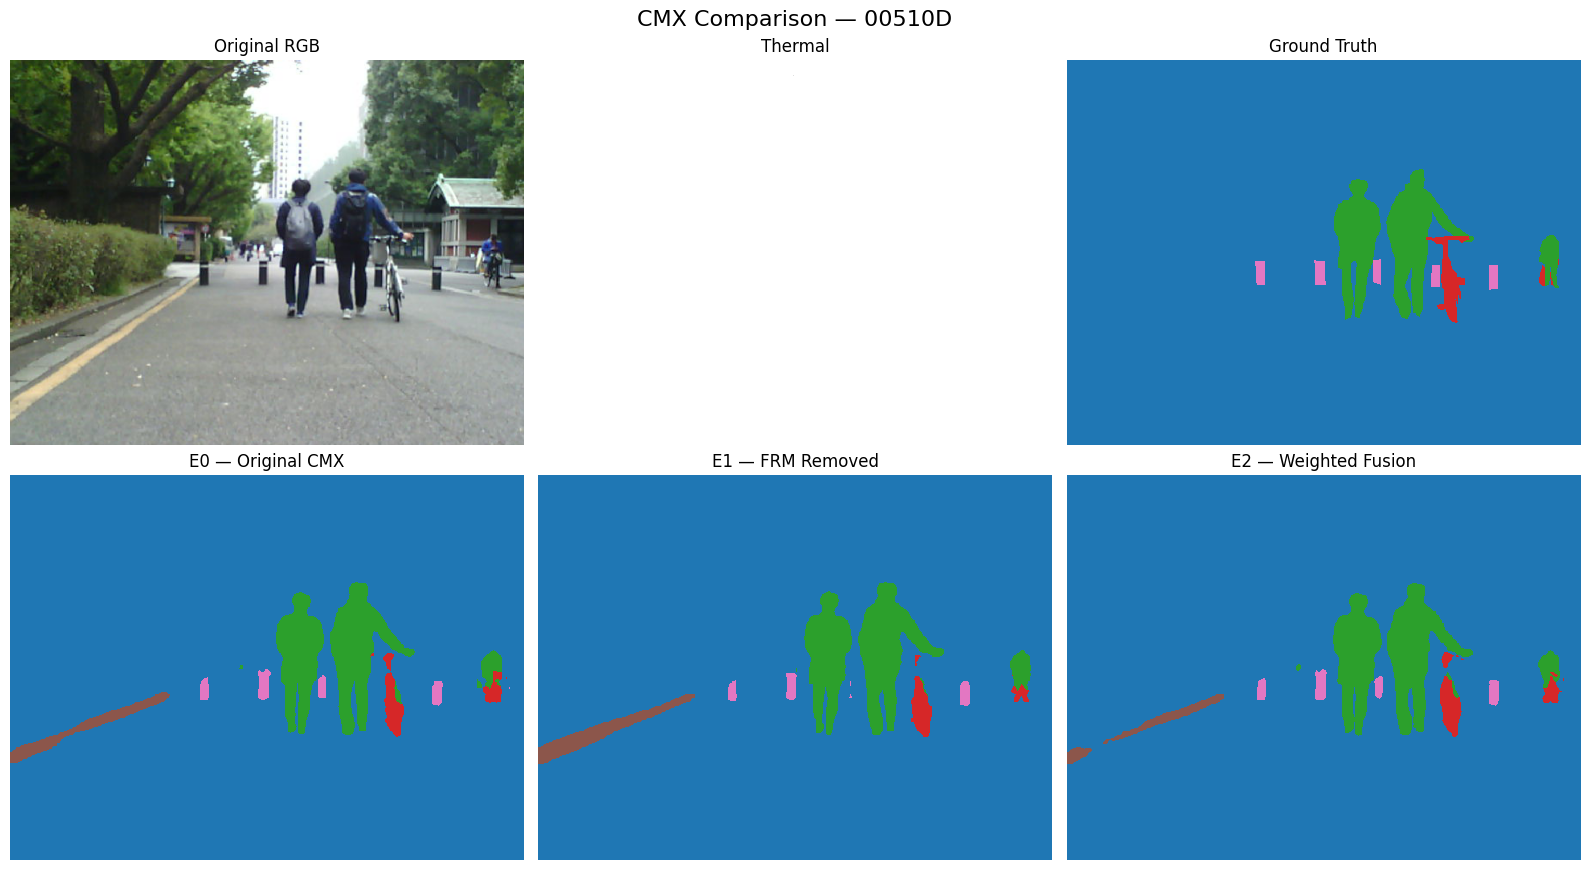

Saved: /home/cse-sdpl/Downloads/CMX_E2/comparison_results/visual_comparison_00510D.png


In [8]:

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Find a new validation image available in all three experiments
common_ids = (
    get_png_ids(E0_PRED_DIR)
    & get_png_ids(E1_PRED_DIR)
    & get_png_ids(E2_PRED_DIR)
    & set(val_ids)
)

IMAGE_ID = "00510D" if "00510D" in common_ids else sorted(common_ids)[10]

print("New image ID:", IMAGE_ID)

rgb = np.array(Image.open(find_png(RGB_DIR, IMAGE_ID)).convert("RGB"))
thermal = np.array(Image.open(find_png(THERMAL_DIR, IMAGE_ID)).convert("L"))
gt = np.array(Image.open(find_png(LABEL_DIR, IMAGE_ID)))
e0 = np.array(Image.open(find_png(E0_PRED_DIR, IMAGE_ID)))
e1 = np.array(Image.open(find_png(E1_PRED_DIR, IMAGE_ID)))
e2 = np.array(Image.open(find_png(E2_PRED_DIR, IMAGE_ID)))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

panels = [
    ("Original RGB", rgb, None),
    ("Thermal", thermal, "gray"),
    ("Ground Truth", gt, "tab10"),
    ("E0 — Original CMX", e0, "tab10"),
    ("E1 — FRM Removed", e1, "tab10"),
    ("E2 — Weighted Fusion", e2, "tab10"),
]

for ax, (title, image, cmap) in zip(axes.flat, panels):
    if cmap:
        ax.imshow(image, cmap=cmap, vmin=0, vmax=8,
                  interpolation="nearest")
    else:
        ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(f"CMX Comparison — {IMAGE_ID}", fontsize=16)
plt.tight_layout()

save_path = RESULTS_DIR / f"visual_comparison_{IMAGE_ID}.png"
plt.savefig(save_path, dpi=250, bbox_inches="tight")
plt.show()

print("Saved:", save_path)


In [9]:

import numpy as np
from PIL import Image

IMAGE_ID = "00498D"

gt = np.array(Image.open(find_png(LABEL_DIR, IMAGE_ID)))
e0 = np.array(Image.open(find_png(E0_PRED_DIR, IMAGE_ID)))
e1 = np.array(Image.open(find_png(E1_PRED_DIR, IMAGE_ID)))
e2 = np.array(Image.open(find_png(E2_PRED_DIR, IMAGE_ID)))

print("Ground truth IDs:", np.unique(gt).tolist())
print("E0 prediction IDs:", np.unique(e0).tolist())
print("E1 prediction IDs:", np.unique(e1).tolist())
print("E2 prediction IDs:", np.unique(e2).tolist())

print("\nGround truth shape:", gt.shape)
print("E2 prediction shape:", e2.shape)

for class_id in range(9):
    gt_pixels = np.sum(gt == class_id)
    pred_pixels = np.sum(e2 == class_id)
    print(
        f"Class {class_id}: "
        f"GT pixels={gt_pixels:6d}, "
        f"E2 predicted pixels={pred_pixels:6d}"
    )


Ground truth IDs: [0, 1, 2, 3, 4, 8]
E0 prediction IDs: [0, 1, 2, 3, 8]
E1 prediction IDs: [0, 1, 2, 3, 8]
E2 prediction IDs: [0, 1, 2, 3, 4, 8]

Ground truth shape: (480, 640)
E2 prediction shape: (480, 640)
Class 0: GT pixels=268709, E2 predicted pixels=284324
Class 1: GT pixels= 12475, E2 predicted pixels=  4289
Class 2: GT pixels=  1749, E2 predicted pixels=  1711
Class 3: GT pixels=  5429, E2 predicted pixels=  4737
Class 4: GT pixels=  7530, E2 predicted pixels=     5
Class 5: GT pixels=     0, E2 predicted pixels=     0
Class 6: GT pixels=     0, E2 predicted pixels=     0
Class 7: GT pixels=     0, E2 predicted pixels=     0
Class 8: GT pixels= 11308, E2 predicted pixels= 12134


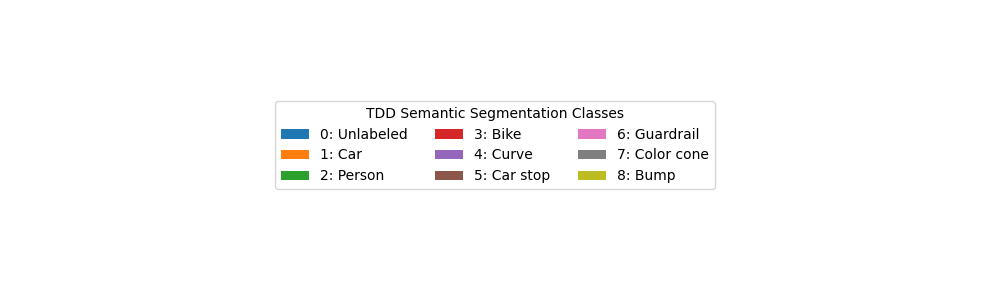

In [10]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

class_names = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

cmap = plt.get_cmap("tab10")

legend_items = [
    Patch(facecolor=cmap(i), label=f"{i}: {name}")
    for i, name in enumerate(class_names)
]

fig, ax = plt.subplots(figsize=(10, 3))
ax.axis("off")
ax.legend(
    handles=legend_items,
    loc="center",
    ncol=3,
    title="TDD Semantic Segmentation Classes",
    frameon=True
)

plt.tight_layout()
plt.show()


Testing new image: 00499D


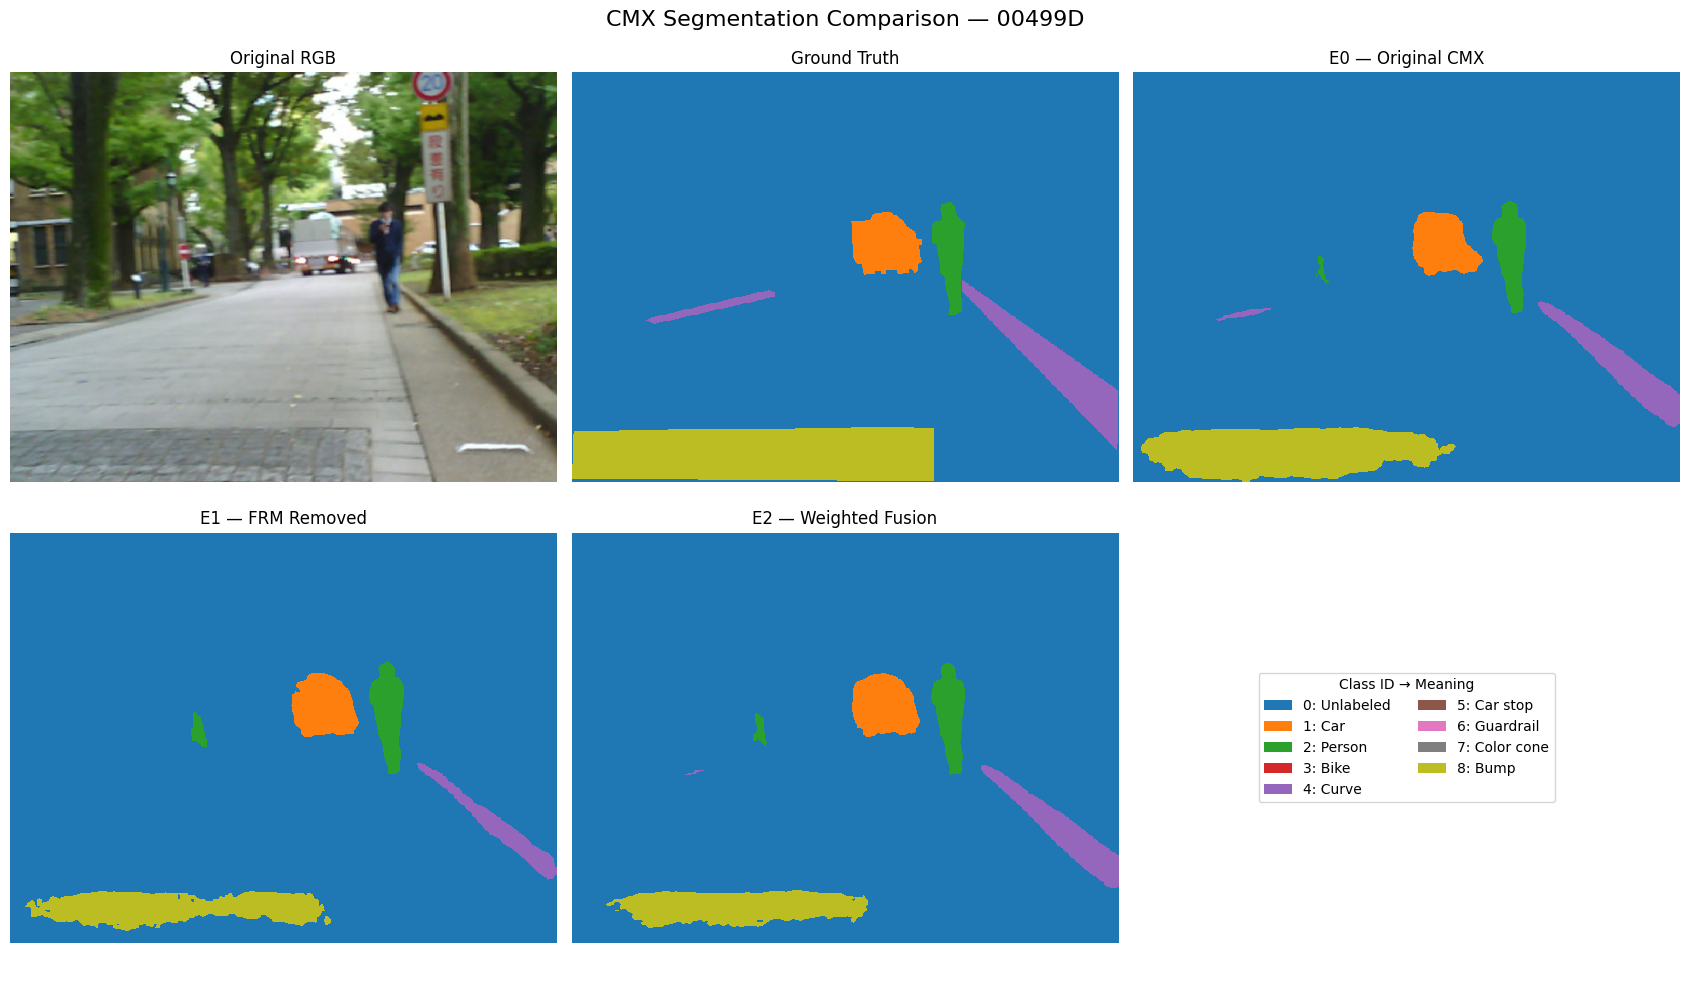

Saved figure: /home/cse-sdpl/Downloads/CMX_E2/comparison_results/labeled_comparison_00499D.png


In [11]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image

# Pick a different image available in all experiments
common_ids = (
    get_png_ids(E0_PRED_DIR)
    & get_png_ids(E1_PRED_DIR)
    & get_png_ids(E2_PRED_DIR)
    & set(val_ids)
)

IMAGE_ID = next(
    image_id for image_id in sorted(common_ids)
    if image_id != "00498D"
)

print("Testing new image:", IMAGE_ID)

# Load the images
rgb = np.array(Image.open(find_png(RGB_DIR, IMAGE_ID)).convert("RGB"))
gt = np.array(Image.open(find_png(LABEL_DIR, IMAGE_ID)))
e0 = np.array(Image.open(find_png(E0_PRED_DIR, IMAGE_ID)))
e1 = np.array(Image.open(find_png(E1_PRED_DIR, IMAGE_ID)))
e2 = np.array(Image.open(find_png(E2_PRED_DIR, IMAGE_ID)))

# Explicit, consistent colors for class IDs 0–8
class_names = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]
colors = plt.get_cmap("tab10").colors[:9]
cmap = ListedColormap(colors)

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

panels = [
    ("Original RGB", rgb, False),
    ("Ground Truth", gt, True),
    ("E0 — Original CMX", e0, True),
    ("E1 — FRM Removed", e1, True),
    ("E2 — Weighted Fusion", e2, True),
]

# First five panels; use the final panel for the color legend
for ax, (title, image, is_mask) in zip(axes.flat, panels):
    if is_mask:
        ax.imshow(image, cmap=cmap, vmin=0, vmax=8,
                  interpolation="nearest")
    else:
        ax.imshow(image)
    ax.set_title(title, fontsize=12)
    ax.axis("off")

axes.flat[5].axis("off")
legend_items = [
    Patch(facecolor=colors[i], label=f"{i}: {class_names[i]}")
    for i in range(9)
]
axes.flat[5].legend(
    handles=legend_items,
    loc="center",
    title="Class ID → Meaning",
    ncol=2,
    fontsize=10
)

fig.suptitle(f"CMX Segmentation Comparison — {IMAGE_ID}", fontsize=16)
plt.tight_layout()

save_path = RESULTS_DIR / f"labeled_comparison_{IMAGE_ID}.png"
plt.savefig(save_path, dpi=250, bbox_inches="tight")
plt.show()

print("Saved figure:", save_path)


 # Create the publication-style visualization

Selected validation scenes: ['00499D', '00500D', '00501D']


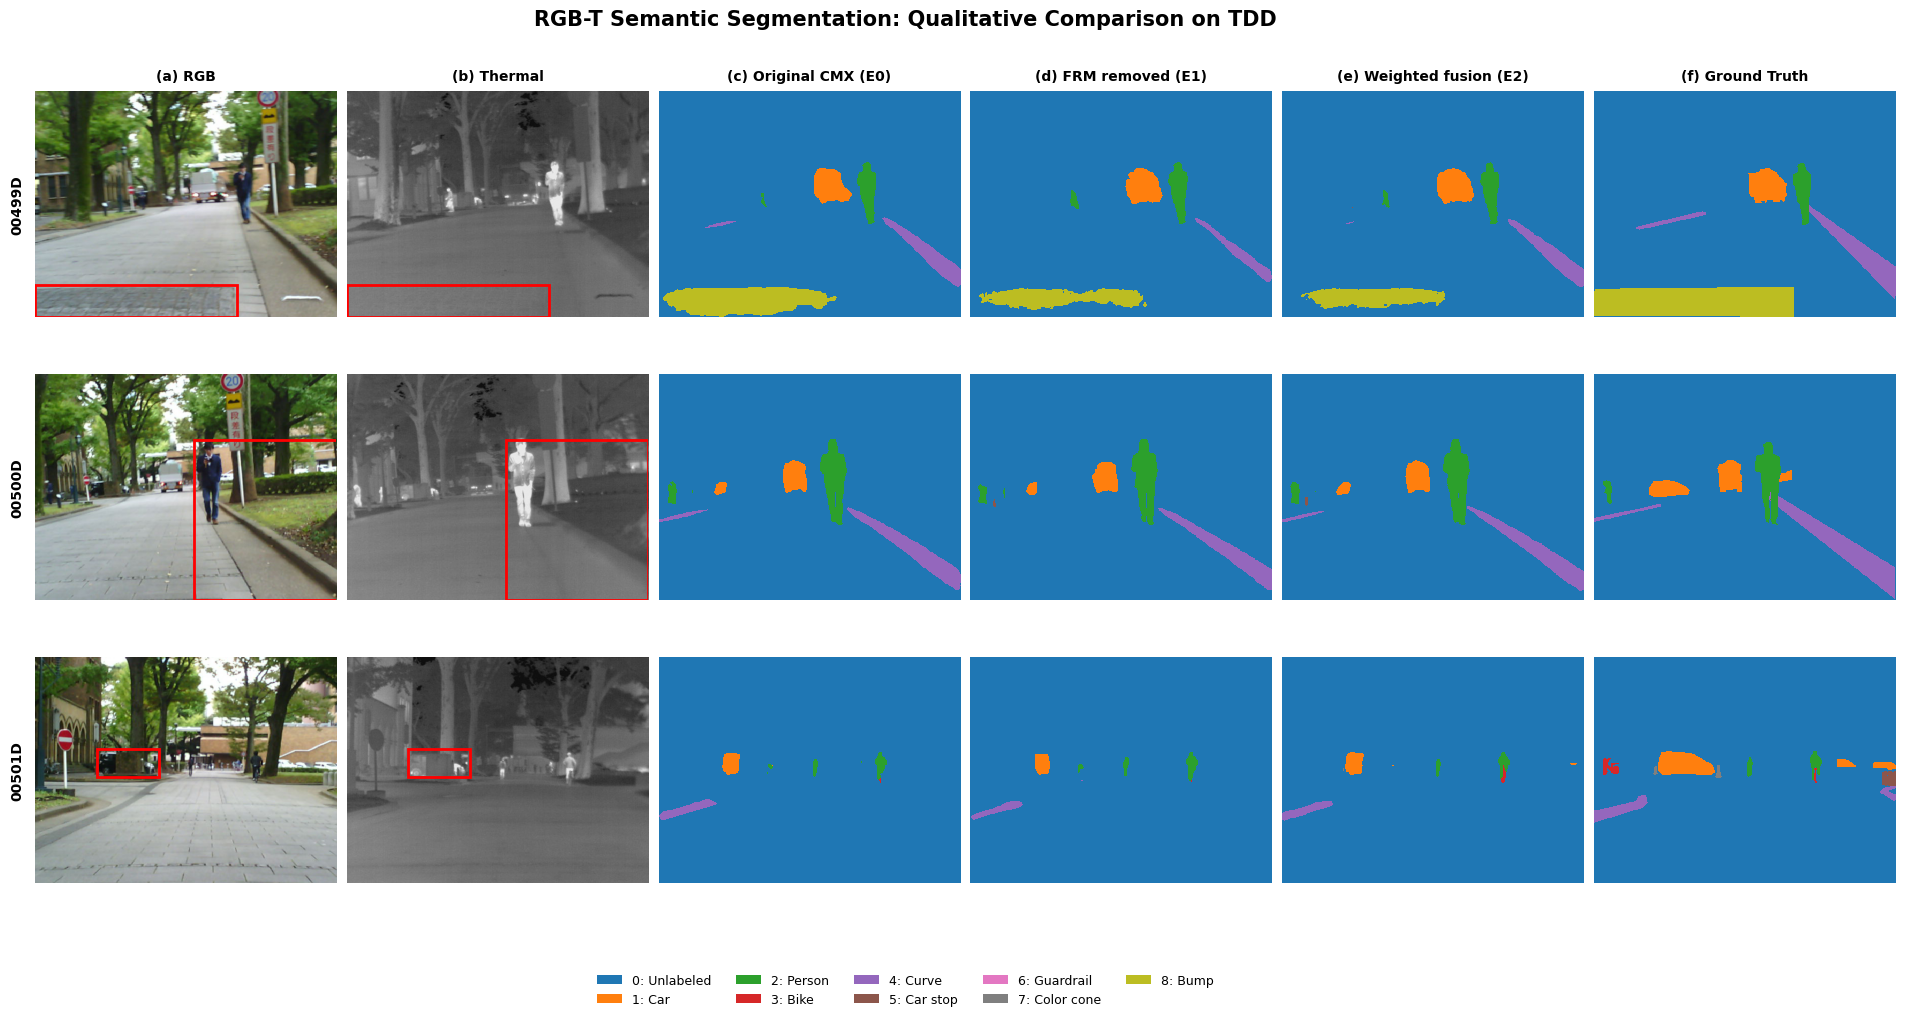


Figure saved successfully:
/home/cse-sdpl/Downloads/CMX_E2/comparison_results/CMX_publication_comparison_v2.png


In [16]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch
from PIL import Image
import cv2

# ============================================================
# 1. PATHS
# ============================================================
BASE = Path("/home/cse-sdpl/Downloads/CMX_Original")
DATA = BASE / "datasets/TDD"

RGB_DIR = DATA / "RGB"
THERMAL_DIR = DATA / "Thermal"
LABEL_DIR = DATA / "Label"
VAL_FILE = DATA / "val.txt"

E0_DIR = BASE / "predictions_TDD_epoch100"
E1_DIR = Path("/home/cse-sdpl/Downloads/CMX_E1/e1_predictions")
E2_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100")

OUT_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2/comparison_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. HELPERS
# ============================================================
def find_png(folder, image_id):
    matches = list(folder.rglob(f"{image_id}.png"))
    if not matches:
        raise FileNotFoundError(
            f"Missing {image_id}.png in {folder}"
        )
    return matches[0]

def read_rgb(image_id):
    return np.asarray(
        Image.open(find_png(RGB_DIR, image_id)).convert("RGB")
    )

def read_thermal(image_id):
    return np.asarray(
        Image.open(find_png(THERMAL_DIR, image_id)).convert("L")
    )

def read_mask(folder, image_id):
    return np.asarray(Image.open(find_png(folder, image_id)))

def available_ids(folder):
    return {p.stem for p in folder.rglob("*.png")}

# ============================================================
# 3. AUTOMATIC OBJECT-REGION BOX
# ============================================================
def find_object_box(gt, min_area=100):
    """
    Finds a bounding box around the largest connected
    non-background region in the GT mask.

    Note: this finds a connected region, not necessarily
    an individual car/person. Class-specific selection
    can be added after inspecting the dataset.
    """
    foreground = (gt > 0).astype(np.uint8)

    count, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(foreground, 8)
    )

    candidates = []

    for i in range(1, count):
        x, y, w, h, area = stats[i]

        if area >= min_area:
            candidates.append((area, x, y, w, h))

    if not candidates:
        return None

    # Largest connected foreground region
    area, x, y, w, h = max(
        candidates, key=lambda item: item[0]
    )

    H, W = gt.shape
    margin = 5

    x1 = max(0, x - margin)
    y1 = max(0, y - margin)
    x2 = min(W, x + w + margin)
    y2 = min(H, y + h + margin)

    return x1, y1, x2 - x1, y2 - y1

# ============================================================
# 4. VALIDATION IMAGE IDS
# ============================================================
val_ids = [
    line.strip().split()[0].replace(".png", "")
    for line in VAL_FILE.read_text().splitlines()
    if line.strip()
]

common_ids = (
    set(val_ids)
    & available_ids(E0_DIR)
    & available_ids(E1_DIR)
    & available_ids(E2_DIR)
)

# Use three common scenes, excluding our earlier example.
IMAGE_IDS = [
    image_id
    for image_id in sorted(common_ids)
    if image_id != "00498D"
][:3]

if len(IMAGE_IDS) != 3:
    raise RuntimeError(
        f"Expected 3 common validation images; found {len(IMAGE_IDS)}"
    )

print("Selected validation scenes:", IMAGE_IDS)

# ============================================================
# 5. CONSISTENT CLASS COLORS
# ============================================================
class_names = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

colors = list(plt.get_cmap("tab10").colors[:9])
mask_cmap = ListedColormap(colors)

titles = [
    "(a) RGB",
    "(b) Thermal",
    "(c) Original CMX (E0)",
    "(d) FRM removed (E1)",
    "(e) Weighted fusion (E2)",
    "(f) Ground Truth"
]

# ============================================================
# 6. CREATE PUBLICATION-STYLE FIGURE
# ============================================================
fig, axes = plt.subplots(
    nrows=3,
    ncols=6,
    figsize=(20, 10.5)
)

for r, image_id in enumerate(IMAGE_IDS):

    rgb = read_rgb(image_id)
    thermal = read_thermal(image_id)
    e0 = read_mask(E0_DIR, image_id)
    e1 = read_mask(E1_DIR, image_id)
    e2 = read_mask(E2_DIR, image_id)
    gt = read_mask(LABEL_DIR, image_id)

    # Verify dimensions match before applying identical boxes.
    shapes = {
        rgb.shape[:2], thermal.shape,
        e0.shape, e1.shape, e2.shape, gt.shape
    }

    if len(shapes) != 1:
        raise ValueError(
            f"Image dimensions do not match for {image_id}: {shapes}"
        )

    panels = [
        (rgb, "rgb"),
        (thermal, "thermal"),
        (e0, "mask"),
        (e1, "mask"),
        (e2, "mask"),
        (gt, "mask")
    ]

    # Find region from the GT mask.
    box = find_object_box(gt)

    for c, (image, kind) in enumerate(panels):
        ax = axes[r, c]

        if kind == "rgb":
            ax.imshow(image)
        elif kind == "thermal":
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(
                image,
                cmap=mask_cmap,
                vmin=0,
                vmax=8,
                interpolation="nearest"
            )

        # Same red box on RGB and thermal only.
        if box is not None and c in (0, 1):
            x, y, w, h = box

            ax.add_patch(
                Rectangle(
                    (x, y),
                    w,
                    h,
                    linewidth=2,
                    edgecolor="red",
                    facecolor="none"
                )
            )

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

        if r == 0:
            ax.set_title(
                titles[c],
                fontsize=10,
                fontweight="semibold",
                pad=8
            )

        if c == 0:
            ax.set_ylabel(
                image_id,
                fontsize=10,
                fontweight="bold",
                labelpad=8
            )

    if box is None:
        print(f"Warning: no suitable foreground region for {image_id}")

# ============================================================
# 7. SHARED CLASS LEGEND AND EXPORT
# ============================================================
legend_handles = [
    Patch(facecolor=colors[i], label=f"{i}: {class_names[i]}")
    for i in range(9)
]

fig.suptitle(
    "RGB-T Semantic Segmentation: Qualitative Comparison on TDD",
    fontsize=15,
    fontweight="bold",
    y=0.975
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    fontsize=9,
    frameon=False,
    bbox_to_anchor=(0.5, 0.015)
)

plt.subplots_adjust(
    left=0.065,
    right=0.995,
    top=0.91,
    bottom=0.13,
    wspace=0.035,
    hspace=0.12
)

output_file = OUT_DIR / "CMX_publication_comparison_v2.png"

fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFigure saved successfully:")
print(output_file)


Selected scenes: ['00499D', '00500D', '00501D']
00499D: 5 region boxes
00500D: 8 region boxes
00501D: 12 region boxes


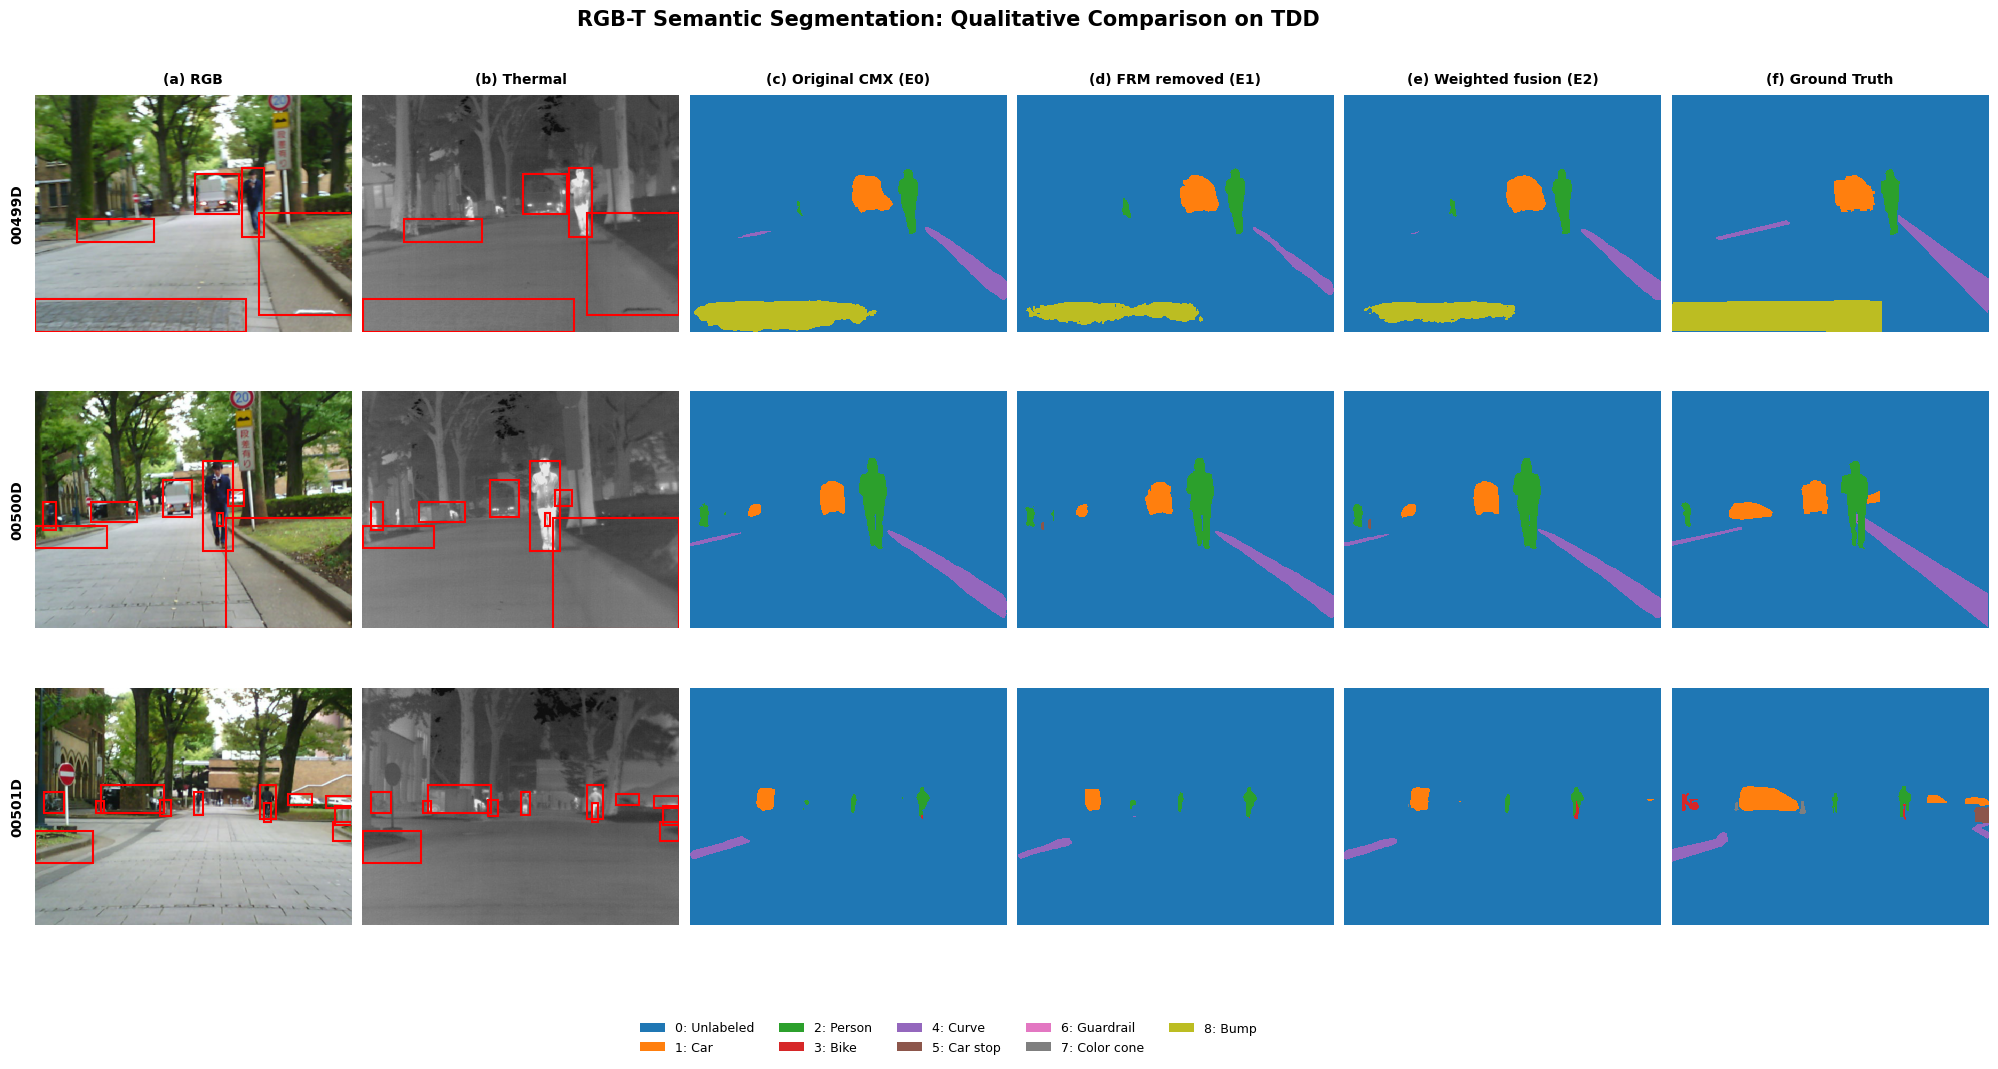


Saved figure to:
/home/cse-sdpl/Downloads/CMX_E2/comparison_results/CMX_publication_comparison_multiple_boxes.png


In [17]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch
from PIL import Image
import cv2

# ============================================================
# 1. DATASET AND PREDICTION PATHS
# ============================================================
BASE = Path("/home/cse-sdpl/Downloads/CMX_Original")
DATA = BASE / "datasets/TDD"

RGB_DIR = DATA / "RGB"
THERMAL_DIR = DATA / "Thermal"
LABEL_DIR = DATA / "Label"
VAL_FILE = DATA / "val.txt"

E0_DIR = BASE / "predictions_TDD_epoch100"
E1_DIR = Path("/home/cse-sdpl/Downloads/CMX_E1/e1_predictions")
E2_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100")

OUT_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2/comparison_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================
def find_png(folder, image_id):
    matches = list(folder.rglob(f"{image_id}.png"))
    if not matches:
        raise FileNotFoundError(
            f"Missing {image_id}.png in {folder}"
        )
    return matches[0]

def read_rgb(image_id):
    return np.asarray(
        Image.open(find_png(RGB_DIR, image_id)).convert("RGB")
    )

def read_thermal(image_id):
    return np.asarray(
        Image.open(find_png(THERMAL_DIR, image_id)).convert("L")
    )

def read_mask(folder, image_id):
    return np.asarray(Image.open(find_png(folder, image_id)))

def available_ids(folder):
    return {p.stem for p in folder.rglob("*.png")}

# ============================================================
# 3. MULTIPLE REGION BOXES FROM GROUND TRUTH
# ============================================================
def find_object_boxes(
    gt,
    min_area=40,
    max_boxes=20,
    margin=3
):
    """
    Finds connected foreground regions separately for each
    nonzero semantic class.

    Returns:
        List of (x, y, width, height, class_id).

    Important:
        Semantic connected regions are not guaranteed to
        correspond to individual physical objects.
    """
    boxes = []
    H, W = gt.shape

    for class_id in np.unique(gt):
        if class_id == 0:
            continue

        binary = (gt == class_id).astype(np.uint8)

        count, labels, stats, centroids = (
            cv2.connectedComponentsWithStats(binary, 8)
        )

        for i in range(1, count):
            x, y, w, h, area = stats[i]

            if area < min_area:
                continue

            # Reject tiny boxes and near-full-image regions.
            if w >= 0.95 * W and h >= 0.95 * H:
                continue

            x1 = max(0, x - margin)
            y1 = max(0, y - margin)
            x2 = min(W, x + w + margin)
            y2 = min(H, y + h + margin)

            boxes.append((
                x1, y1, x2 - x1, y2 - y1, int(class_id)
            ))

    # Larger regions first; cap the total number of boxes.
    boxes.sort(key=lambda b: b[2] * b[3], reverse=True)

    return boxes[:max_boxes]

# ============================================================
# 4. SELECT VALIDATION IMAGES COMMON TO E0/E1/E2
# ============================================================
val_ids = [
    line.strip().split()[0].replace(".png", "")
    for line in VAL_FILE.read_text().splitlines()
    if line.strip()
]

common_ids = (
    set(val_ids)
    & available_ids(E0_DIR)
    & available_ids(E1_DIR)
    & available_ids(E2_DIR)
)

IMAGE_IDS = [
    image_id for image_id in sorted(common_ids)
    if image_id != "00498D"
][:3]

if len(IMAGE_IDS) != 3:
    raise RuntimeError(
        f"Expected 3 common images; found {len(IMAGE_IDS)}"
    )

print("Selected scenes:", IMAGE_IDS)

# ============================================================
# 5. CONSISTENT CLASS COLORS AND TITLES
# ============================================================
class_names = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

colors = list(plt.get_cmap("tab10").colors[:9])
mask_cmap = ListedColormap(colors)

titles = [
    "(a) RGB",
    "(b) Thermal",
    "(c) Original CMX (E0)",
    "(d) FRM removed (E1)",
    "(e) Weighted fusion (E2)",
    "(f) Ground Truth"
]

# ============================================================
# 6. DRAW THE COMPARISON FIGURE
# ============================================================
fig, axes = plt.subplots(
    nrows=3,
    ncols=6,
    figsize=(21, 11)
)

for r, image_id in enumerate(IMAGE_IDS):

    rgb = read_rgb(image_id)
    thermal = read_thermal(image_id)

    e0 = read_mask(E0_DIR, image_id)
    e1 = read_mask(E1_DIR, image_id)
    e2 = read_mask(E2_DIR, image_id)
    gt = read_mask(LABEL_DIR, image_id)

    # Ensure the modalities and masks have matching dimensions.
    shapes = {
        rgb.shape[:2], thermal.shape,
        e0.shape, e1.shape, e2.shape, gt.shape
    }

    if len(shapes) != 1:
        raise ValueError(
            f"Dimension mismatch for {image_id}: {shapes}"
        )

    panels = [
        (rgb, "rgb"),
        (thermal, "thermal"),
        (e0, "mask"),
        (e1, "mask"),
        (e2, "mask"),
        (gt, "mask")
    ]

    # Multiple boxes generated once, then reused on both modalities.
    boxes = find_object_boxes(
        gt,
        min_area=40,
        max_boxes=20,
        margin=3
    )

    print(f"{image_id}: {len(boxes)} region boxes")

    for c, (image, kind) in enumerate(panels):
        ax = axes[r, c]

        if kind == "rgb":
            ax.imshow(image)
        elif kind == "thermal":
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(
                image,
                cmap=mask_cmap,
                vmin=0,
                vmax=8,
                interpolation="nearest"
            )

        # Identical boxes in RGB and thermal.
        if c in (0, 1):
            for x, y, w, h, class_id in boxes:
                ax.add_patch(
                    Rectangle(
                        (x, y),
                        w,
                        h,
                        linewidth=1.5,
                        edgecolor="red",
                        facecolor="none"
                    )
                )

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

        if r == 0:
            ax.set_title(
                titles[c],
                fontsize=10,
                fontweight="semibold",
                pad=8
            )

        if c == 0:
            ax.set_ylabel(
                image_id,
                fontsize=10,
                fontweight="bold",
                labelpad=8
            )

# ============================================================
# 7. SHARED CLASS LEGEND
# ============================================================
legend_handles = [
    Patch(
        facecolor=colors[i],
        label=f"{i}: {class_names[i]}"
    )
    for i in range(9)
]

fig.suptitle(
    "RGB-T Semantic Segmentation: Qualitative Comparison on TDD",
    fontsize=15,
    fontweight="bold",
    y=0.975
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    fontsize=9,
    frameon=False,
    bbox_to_anchor=(0.5, 0.015)
)

plt.subplots_adjust(
    left=0.065,
    right=0.995,
    top=0.91,
    bottom=0.13,
    wspace=0.035,
    hspace=0.12
)

# ============================================================
# 8. SAVE HIGH-RESOLUTION FIGURE
# ============================================================
output_file = OUT_DIR / "CMX_publication_comparison_multiple_boxes.png"

fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nSaved figure to:")
print(output_file)


Validation images: 392

Evaluating E0...
  Processed 100/392
  Processed 200/392
  Processed 300/392

Evaluating E1...
  Processed 100/392
  Processed 200/392
  Processed 300/392

Evaluating E2...
  Processed 100/392
  Processed 200/392
  Processed 300/392

OVERALL VALIDATION METRICS


,mIoU (%),Pixel Accuracy (%),Mean Pixel Accuracy (%),Frequency Weighted IoU (%)
Model,,,,
E0,62.726,97.732,72.982,95.784
E1,60.944,97.684,70.880,95.678
E2,62.325,97.731,72.627,95.773



PER-CLASS IoU COMPARISON


,Class,E0 IoU (%),E1 IoU (%),E2 IoU (%),E1 - E0 (pp),E2 - E0 (pp),E2 - E1 (pp)
0,Unlabeled,97.775,97.726,97.783,-0.049,0.008,0.058
1,Car,87.045,87.001,86.555,-0.045,-0.490,-0.445
2,Person,71.804,71.608,71.449,-0.196,-0.355,-0.159
3,Bike,72.866,72.682,73.042,-0.185,0.176,0.360
4,Curve,38.150,36.603,38.948,-1.546,0.798,2.344
5,Car stop,39.068,32.581,41.058,-6.488,1.989,8.477
6,Guardrail,48.623,45.387,45.470,-3.236,-3.153,0.083
7,Color cone,58.333,56.540,58.579,-1.793,0.246,2.039
8,Bump,50.866,48.367,48.038,-2.499,-2.828,-0.329


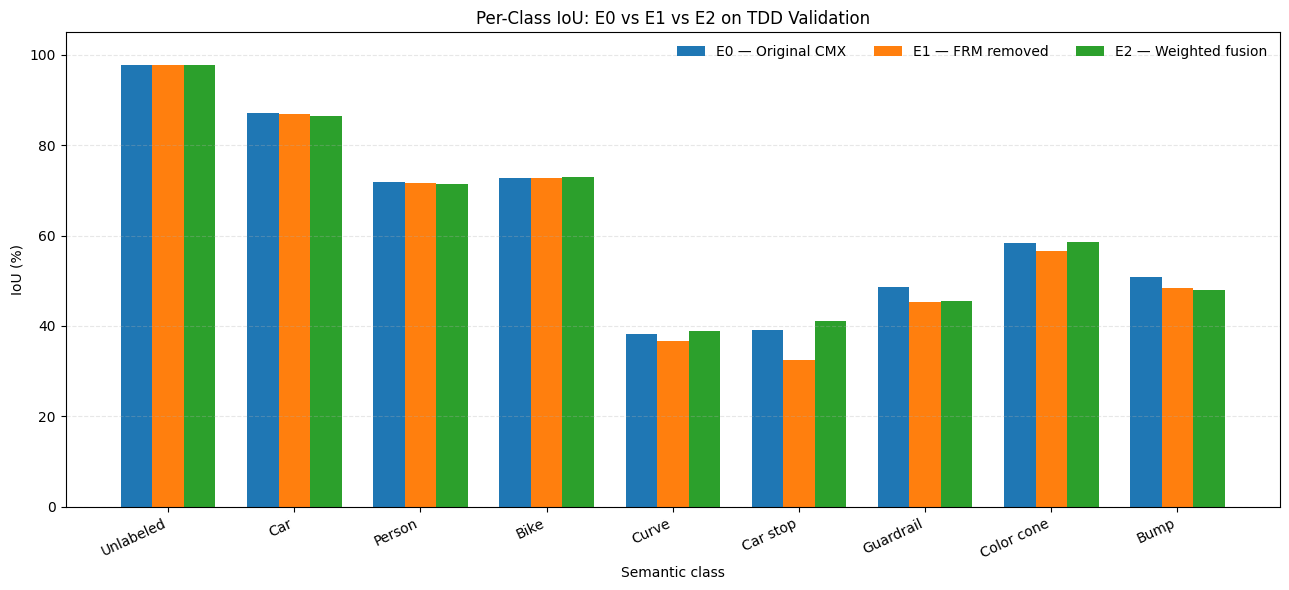


Saved results to: /home/cse-sdpl/Downloads/CMX_E2/comparison_results
Overall metrics: overall_metrics_recomputed.csv
Class metrics:   per_class_iou_comparison.csv
IoU chart:       per_class_iou_comparison.png


In [18]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ============================================================
# 1. PATHS
# ============================================================
BASE = Path("/home/cse-sdpl/Downloads/CMX_Original")
DATA = BASE / "datasets/TDD"

GT_DIR = DATA / "Label"
VAL_FILE = DATA / "val.txt"

PRED_DIRS = {
    "E0": BASE / "predictions_TDD_epoch100",
    "E1": Path("/home/cse-sdpl/Downloads/CMX_E1/e1_predictions"),
    "E2": Path("/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100"),
}

OUT_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2/comparison_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

NUM_CLASSES = 9

CLASS_NAMES = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

# ============================================================
# 2. HELPERS
# ============================================================
def find_png(folder, image_id):
    matches = list(folder.rglob(f"{image_id}.png"))
    if not matches:
        raise FileNotFoundError(
            f"Missing {image_id}.png in {folder}"
        )
    return matches[0]

def read_mask(folder, image_id):
    return np.asarray(Image.open(find_png(folder, image_id)))

val_ids = [
    line.strip().split()[0].replace(".png", "")
    for line in VAL_FILE.read_text().splitlines()
    if line.strip()
]

print("Validation images:", len(val_ids))

# ============================================================
# 3. COMPUTE CONFUSION MATRIX ON THE SAME VALIDATION SET
# ============================================================
def evaluate_predictions(pred_folder, image_ids):
    confusion = np.zeros(
        (NUM_CLASSES, NUM_CLASSES), dtype=np.int64
    )

    for index, image_id in enumerate(image_ids, start=1):
        gt = read_mask(GT_DIR, image_id).astype(np.int64)
        pred = read_mask(pred_folder, image_id).astype(np.int64)

        if gt.shape != pred.shape:
            raise ValueError(
                f"Shape mismatch for {image_id}: "
                f"GT={gt.shape}, prediction={pred.shape}"
            )

        valid = (
            (gt >= 0) & (gt < NUM_CLASSES) &
            (pred >= 0) & (pred < NUM_CLASSES)
        )

        gt_valid = gt[valid]
        pred_valid = pred[valid]

        counts = np.bincount(
            NUM_CLASSES * gt_valid + pred_valid,
            minlength=NUM_CLASSES ** 2
        )

        confusion += counts.reshape(NUM_CLASSES, NUM_CLASSES)

        if index % 100 == 0:
            print(f"  Processed {index}/{len(image_ids)}")

    # Rows = GT classes; columns = predicted classes
    true_positive = np.diag(confusion)
    gt_count = confusion.sum(axis=1)
    pred_count = confusion.sum(axis=0)
    union = gt_count + pred_count - true_positive

    iou = np.divide(
        true_positive, union,
        out=np.full(NUM_CLASSES, np.nan),
        where=union > 0
    )

    class_accuracy = np.divide(
        true_positive, gt_count,
        out=np.full(NUM_CLASSES, np.nan),
        where=gt_count > 0
    )

    total_pixels = confusion.sum()
    pixel_accuracy = (
        true_positive.sum() / total_pixels
        if total_pixels else np.nan
    )

    mean_iou = np.nanmean(iou)
    mean_pixel_accuracy = np.nanmean(class_accuracy)

    frequency = gt_count / total_pixels
    frequency_weighted_iou = np.nansum(frequency * iou)

    return {
        "confusion": confusion,
        "iou": iou,
        "class_accuracy": class_accuracy,
        "mIoU": mean_iou,
        "pixel_accuracy": pixel_accuracy,
        "mean_pixel_accuracy": mean_pixel_accuracy,
        "frequency_weighted_iou": frequency_weighted_iou,
    }

# Ensure every model has every validation prediction.
def get_ids(folder):
    return {p.stem for p in folder.rglob("*.png")}

for model, folder in PRED_DIRS.items():
    missing = set(val_ids) - get_ids(folder)
    if missing:
        raise RuntimeError(
            f"{model} is missing {len(missing)} validation predictions. "
            f"Examples: {sorted(missing)[:5]}"
        )

# ============================================================
# 4. EVALUATE E0, E1, E2
# ============================================================
results = {}

for model, folder in PRED_DIRS.items():
    print(f"\nEvaluating {model}...")
    results[model] = evaluate_predictions(folder, val_ids)

# ============================================================
# 5. OVERALL METRICS TABLE
# ============================================================
metric_rows = []

for model, result in results.items():
    metric_rows.append({
        "Model": model,
        "mIoU (%)": result["mIoU"] * 100,
        "Pixel Accuracy (%)": result["pixel_accuracy"] * 100,
        "Mean Pixel Accuracy (%)":
            result["mean_pixel_accuracy"] * 100,
        "Frequency Weighted IoU (%)":
            result["frequency_weighted_iou"] * 100,
    })

metrics_df = pd.DataFrame(metric_rows).set_index("Model")

print("\nOVERALL VALIDATION METRICS")
display(metrics_df.round(3))

metrics_df.to_csv(OUT_DIR / "overall_metrics_recomputed.csv")

# ============================================================
# 6. PER-CLASS IoU TABLE
# ============================================================
class_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "E0 IoU (%)": results["E0"]["iou"] * 100,
    "E1 IoU (%)": results["E1"]["iou"] * 100,
    "E2 IoU (%)": results["E2"]["iou"] * 100,
})

class_df["E1 - E0 (pp)"] = (
    class_df["E1 IoU (%)"] - class_df["E0 IoU (%)"]
)
class_df["E2 - E0 (pp)"] = (
    class_df["E2 IoU (%)"] - class_df["E0 IoU (%)"]
)
class_df["E2 - E1 (pp)"] = (
    class_df["E2 IoU (%)"] - class_df["E1 IoU (%)"]
)

print("\nPER-CLASS IoU COMPARISON")
display(class_df.round(3))

class_df.to_csv(OUT_DIR / "per_class_iou_comparison.csv", index=False)

# ============================================================
# 7. PUBLICATION-STYLE PER-CLASS IoU CHART
# ============================================================
x = np.arange(NUM_CLASSES)
width = 0.25

fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(x - width, class_df["E0 IoU (%)"], width, label="E0 — Original CMX")
ax.bar(x,         class_df["E1 IoU (%)"], width, label="E1 — FRM removed")
ax.bar(x + width, class_df["E2 IoU (%)"], width, label="E2 — Weighted fusion")

ax.set_ylabel("IoU (%)")
ax.set_xlabel("Semantic class")
ax.set_title("Per-Class IoU: E0 vs E1 vs E2 on TDD Validation")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=25, ha="right")
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(frameon=False, ncol=3)
fig.tight_layout()

chart_path = OUT_DIR / "per_class_iou_comparison.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved results to:", OUT_DIR)
print("Overall metrics: overall_metrics_recomputed.csv")
print("Class metrics:   per_class_iou_comparison.csv")
print("IoU chart:       per_class_iou_comparison.png")


Selected diagnostic image: 01007N
Pixels where E0 and E2 differ: 16263


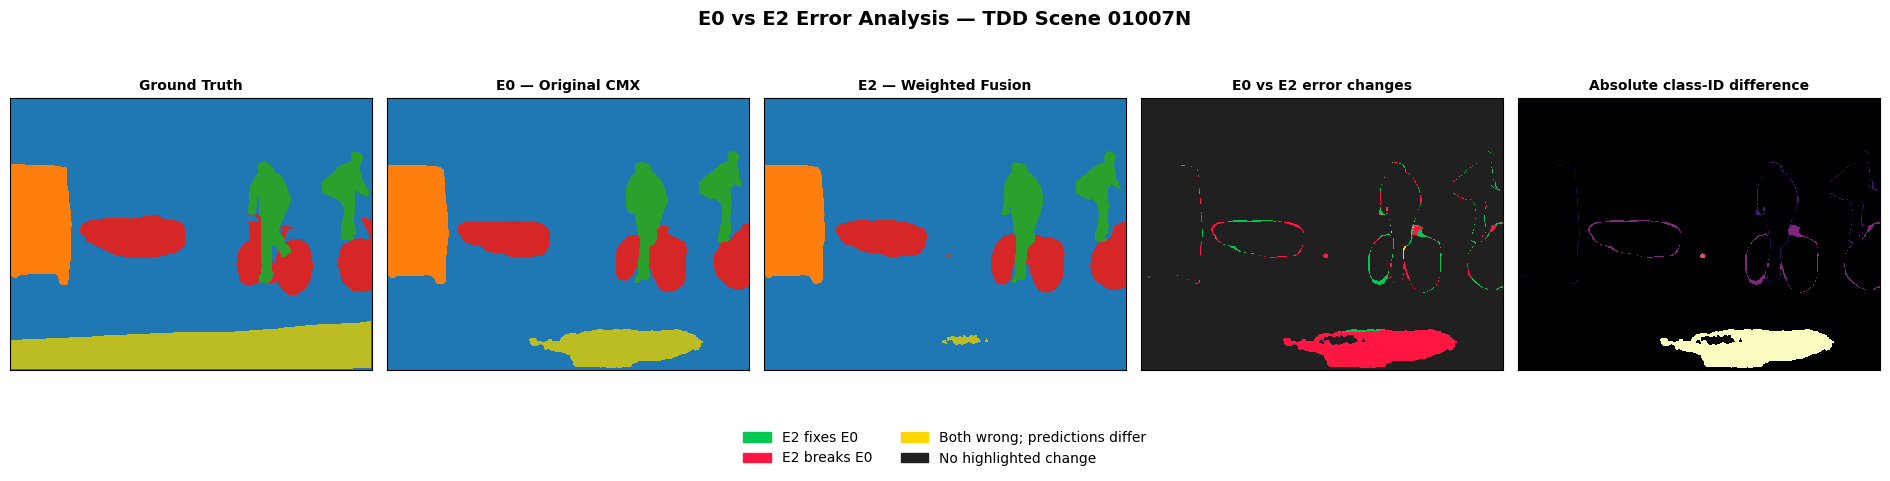


SCENE SUMMARY
Image ID: 01007N
Valid pixels: 307,200
E0 correct pixels: 269,517
E2 correct pixels: 257,139
Pixels E2 fixes: 1,908
Pixels E2 breaks: 14,286
Saved figure: /home/cse-sdpl/Downloads/CMX_E2/comparison_results/E0_E2_error_analysis_01007N.png


In [19]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ============================================================
# PATHS
# ============================================================
BASE = Path("/home/cse-sdpl/Downloads/CMX_Original")
DATA = BASE / "datasets/TDD"

GT_DIR = DATA / "Label"
VAL_FILE = DATA / "val.txt"

E0_DIR = BASE / "predictions_TDD_epoch100"
E2_DIR = Path(
    "/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100"
)

OUT_DIR = Path(
    "/home/cse-sdpl/Downloads/CMX_E2/comparison_results"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

NUM_CLASSES = 9
CLASS_NAMES = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

def find_png(folder, image_id):
    matches = list(folder.rglob(f"{image_id}.png"))
    if not matches:
        raise FileNotFoundError(
            f"Missing {image_id}.png in {folder}"
        )
    return matches[0]

def read_mask(folder, image_id):
    return np.asarray(
        Image.open(find_png(folder, image_id))
    ).astype(np.int64)

val_ids = [
    line.strip().split()[0].replace(".png", "")
    for line in VAL_FILE.read_text().splitlines()
    if line.strip()
]

# ============================================================
# CHOOSE THE IMAGE WHERE E0 AND E2 DIFFER MOST
# ============================================================
# This is a diagnostic selection, not an unbiased final example.
# We will inspect the selected scene before drawing conclusions.

best_image = None
best_difference = -1

for image_id in val_ids:
    gt = read_mask(GT_DIR, image_id)
    e0 = read_mask(E0_DIR, image_id)
    e2 = read_mask(E2_DIR, image_id)

    if gt.shape != e0.shape or gt.shape != e2.shape:
        raise ValueError(f"Shape mismatch: {image_id}")

    valid = (
        (gt >= 0) & (gt < NUM_CLASSES) &
        (e0 >= 0) & (e0 < NUM_CLASSES) &
        (e2 >= 0) & (e2 < NUM_CLASSES)
    )

    difference = np.count_nonzero(
        (e0[valid] != e2[valid])
    )

    if difference > best_difference:
        best_difference = difference
        best_image = image_id

print("Selected diagnostic image:", best_image)
print("Pixels where E0 and E2 differ:", best_difference)

# ============================================================
# LOAD SELECTED SCENE
# ============================================================
gt = read_mask(GT_DIR, best_image)
e0 = read_mask(E0_DIR, best_image)
e2 = read_mask(E2_DIR, best_image)

valid = (
    (gt >= 0) & (gt < NUM_CLASSES) &
    (e0 >= 0) & (e0 < NUM_CLASSES) &
    (e2 >= 0) & (e2 < NUM_CLASSES)
)

# Correctness is defined against Ground Truth.
e0_correct = (e0 == gt) & valid
e2_correct = (e2 == gt) & valid

# E2 corrects an error made by E0.
e2_fixes_e0 = (~e0_correct) & e2_correct

# E2 makes an error where E0 was correct.
e2_breaks_e0 = e0_correct & (~e2_correct)

# Both wrong, but with different predicted classes.
both_wrong_different = (
    (~e0_correct) & (~e2_correct) & (e0 != e2) & valid
)

# Visualization palette:
# Black = not highlighted, green = E2 fixes E0,
# red = E2 breaks an E0-correct pixel,
# yellow = both wrong and disagree.
change_map = np.zeros(gt.shape, dtype=np.uint8)
change_map[e2_fixes_e0] = 1
change_map[e2_breaks_e0] = 2
change_map[both_wrong_different] = 3

change_cmap = ListedColormap([
    "#202020",  # no highlighted change
    "#00C853",  # E2 fixes E0
    "#FF1744",  # E2 breaks E0
    "#FFD600",  # both wrong, predictions differ
])

# ============================================================
# FIGURE
# ============================================================
fig, axes = plt.subplots(1, 5, figsize=(19, 4.5))

panels = [
    (gt, "Ground Truth"),
    (e0, "E0 — Original CMX"),
    (e2, "E2 — Weighted Fusion"),
    (change_map, "E0 vs E2 error changes"),
    (np.abs(e0 - e2), "Absolute class-ID difference")
]

for ax, (image, title) in zip(axes, panels):
    if title == "E0 vs E2 error changes":
        ax.imshow(image, cmap=change_cmap, vmin=0, vmax=3,
                  interpolation="nearest")
    elif title == "Absolute class-ID difference":
        ax.imshow(image, cmap="magma", interpolation="nearest")
    else:
        ax.imshow(
            image,
            cmap=ListedColormap(
                list(plt.get_cmap("tab10").colors[:NUM_CLASSES])
            ),
            vmin=0, vmax=8,
            interpolation="nearest"
        )

    ax.set_title(title, fontsize=10, fontweight="semibold")
    ax.set_xticks([])
    ax.set_yticks([])

legend_handles = [
    Patch(color="#00C853", label="E2 fixes E0"),
    Patch(color="#FF1744", label="E2 breaks E0"),
    Patch(color="#FFD600", label="Both wrong; predictions differ"),
    Patch(color="#202020", label="No highlighted change")
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, -0.06)
)

fig.suptitle(
    f"E0 vs E2 Error Analysis — TDD Scene {best_image}",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0.12, 1, 0.92])

out_file = OUT_DIR / f"E0_E2_error_analysis_{best_image}.png"
fig.savefig(out_file, dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# NUMERICAL SUMMARY
# ============================================================
n_valid = int(valid.sum())
n_e0_correct = int(e0_correct.sum())
n_e2_correct = int(e2_correct.sum())
n_fixed = int(e2_fixes_e0.sum())
n_broken = int(e2_breaks_e0.sum())

print("\nSCENE SUMMARY")
print(f"Image ID: {best_image}")
print(f"Valid pixels: {n_valid:,}")
print(f"E0 correct pixels: {n_e0_correct:,}")
print(f"E2 correct pixels: {n_e2_correct:,}")
print(f"Pixels E2 fixes: {n_fixed:,}")
print(f"Pixels E2 breaks: {n_broken:,}")
print(f"Saved figure: {out_file}")


In [ ]:

from pathlib import Path
import shutil

source = Path("/home/cse-sdpl/Downloads/CMX_E2")
destination = Path("/home/cse-sdpl/Downloads/CMX_E3")

assert source.is_dir(), f"E2 project not found: {source}"

if destination.exists():
    print("CMX_E3 already exists. Nothing copied or overwritten.")
else:
    shutil.copytree(
        source,
        destination,
        ignore=shutil.ignore_patterns(
            ".git",
            "__pycache__",
            "*.pyc"
        )
    )
    print("CMX_E3 created successfully!")

print("E2:", source)
print("E3:", destination)
